<a href="https://colab.research.google.com/github/Matias-G-Yanez/DCIII-pipeline-base-1er-pre-entrega/blob/main/pipline_base_1er_pre_entrega.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pre-entrega: Pipeline de Entrenamiento, Validación y Clasificador Base
Infraestructura técnica inicial en PyTorch con detección automática de hardware, arquitectura modular (`nn.Module`), ciclo de entrenamiento con `autograd` y evaluación en validación.

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

# 1. Fijar semillas de aleatoriedad para reproducibilidad
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# 2. Detección automática de dispositivo (GPU / MPS / CPU)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Versión de PyTorch: {torch.__version__}")
print(f"Dispositivo seleccionado: {device}")

Versión de PyTorch: 2.11.0+cu130
Dispositivo seleccionado: cuda


## 1. Carga y Preparación del Dataset
Generamos un dataset de clasificación multiclase de referencia, realizamos una partición estratificada en entrenamiento (80%) y validación (20%) para evaluar datos no vistos, y empaquetamos los tensores en `DataLoader` para iterar por mini-batches.

In [2]:
# 1. Generación de dataset sintético multiclase (1200 muestras, 20 features, 3 clases)
X, y = make_classification(
    n_samples=1200,
    n_features=20,
    n_informative=14,
    n_redundant=4,
    n_classes=3,
    random_state=42
)

# 2. División en Entrenamiento (80%) y Validación (20%) estratificada
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Conversión a tensores de PyTorch y creación de TensorDatasets
# Features en float32 y etiquetas de clase en long (int64) para CrossEntropyLoss
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long)
)

# 4. Configuración de DataLoaders
BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Muestras de entrenamiento: {len(train_dataset)} ({len(train_loader)} batches)")
print(f"Muestras de validación:    {len(val_dataset)} ({len(val_loader)} batches)")

Muestras de entrenamiento: 960 (30 batches)
Muestras de validación:    240 (8 batches)


## 2. Definición de la Arquitectura Base (`nn.Module`)
Diseñamos un Perceptrón Multicapa (MLP) modular heredando de `nn.Module`. Incluye capas lineales con activaciones no lineales `ReLU` y una capa de salida que entrega logits crudos para las 3 clases.

In [3]:
class BaseClassifier(nn.Module):
    def __init__(self, in_features=20, hidden_dim=64, num_classes=3):
        super(BaseClassifier, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)  # Salida de logits (sin Softmax porque CrossEntropyLoss ya lo incluye)
        )

    def forward(self, x):
        return self.network(x)

# Instanciamos el modelo y lo enviamos al dispositivo detectado (cuda)
model = BaseClassifier(in_features=20, hidden_dim=64, num_classes=3).to(device)

print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal de parámetros entrenables: {total_params}")

BaseClassifier(
  (network): Sequential(
    (0): Linear(in_features=20, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=3, bias=True)
  )
)

Total de parámetros entrenables: 3523


## 3. Pipeline de Entrenamiento y Validación
Implementamos la función de evaluación separada (`evaluate`) sin cálculo de gradientes (`torch.no_grad()`) y el bucle principal de entrenamiento utilizando `CrossEntropyLoss` y el optimizador `Adam` (`lr=0.001`), registrando pérdida y Accuracy por época.

In [4]:
# Configuración de función de pérdida y optimizador
LEARNING_RATE = 0.001
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Función de evaluación separada para el conjunto de validación
def evaluate(model, data_loader, criterion, device):
    model.eval()  # Modo evaluación (desactiva comportamientos específicos de entrenamiento)
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():  # Desactiva el motor autograd para ahorrar memoria y cómputo
        for inputs, targets in data_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * inputs.size(0)
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == targets).sum().item()
            total += targets.size(0)

    avg_loss = running_loss / total
    accuracy = correct / total
    return avg_loss, accuracy

# Ciclo de Entrenamiento (Training Loop)
EPOCHS = 25
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(EPOCHS):
    model.train()  # Modo entrenamiento
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in train_loader:
        # Enviar tensores al mismo dispositivo que el modelo (cuda)
        inputs, targets = inputs.to(device), targets.to(device)

        # 1. Reiniciar gradientes acumulados
        optimizer.zero_grad()

        # 2. Forward pass: obtener predicciones (logits)
        outputs = model(inputs)

        # 3. Calcular la pérdida
        loss = criterion(outputs, targets)

        # 4. Backward pass: calcular gradientes automáticamente con autograd
        loss.backward()

        # 5. Actualizar pesos con el optimizador Adam
        optimizer.step()

        # Acumular métricas del batch
        running_loss += loss.item() * inputs.size(0)
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == targets).sum().item()
        total += targets.size(0)

    # Métricas promedio de la época en entrenamiento
    train_loss = running_loss / total
    train_acc = correct / total

    # Evaluación en el conjunto de validación ("datos no vistos")
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    # Guardar en el historial para graficar
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Época [{epoch+1:02d}/{EPOCHS}] | "
              f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | "
              f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%")

Época [01/25] | Train Loss: 1.0485 - Train Acc: 48.12% | Val Loss: 0.9835 - Val Acc: 60.00%
Época [05/25] | Train Loss: 0.5242 - Train Acc: 79.58% | Val Loss: 0.5898 - Val Acc: 76.67%
Época [10/25] | Train Loss: 0.3323 - Train Acc: 87.60% | Val Loss: 0.4433 - Val Acc: 82.50%
Época [15/25] | Train Loss: 0.2331 - Train Acc: 91.88% | Val Loss: 0.3764 - Val Acc: 85.42%
Época [20/25] | Train Loss: 0.1682 - Train Acc: 94.79% | Val Loss: 0.3532 - Val Acc: 87.50%
Época [25/25] | Train Loss: 0.1255 - Train Acc: 96.15% | Val Loss: 0.3322 - Val Acc: 88.75%


## 4. Visualización de Curvas de Aprendizaje
Generamos las gráficas de evolución de pérdida y precisión tanto para el conjunto de entrenamiento como para validación, permitiendo auditar visualmente la convergencia del modelo.

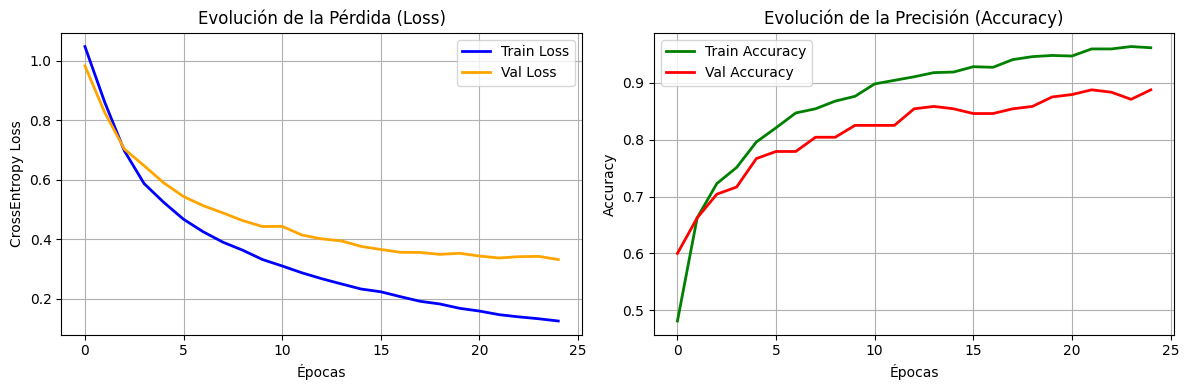

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico de Pérdida (Loss)
axes[0].plot(history["train_loss"], label="Train Loss", color="blue", linewidth=2)
axes[0].plot(history["val_loss"], label="Val Loss", color="orange", linewidth=2)
axes[0].set_title("Evolución de la Pérdida (Loss)")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("CrossEntropy Loss")
axes[0].legend()
axes[0].grid(True)

# Gráfico de Precisión (Accuracy)
axes[1].plot(history["train_acc"], label="Train Accuracy", color="green", linewidth=2)
axes[1].plot(history["val_acc"], label="Val Accuracy", color="red", linewidth=2)
axes[1].set_title("Evolución de la Precisión (Accuracy)")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("loss_curve.png", dpi=300)
plt.show()